<sub>**The Annotated ML Handbook** · Part IV: Visualization · by Mahir Absar Khan</sub>

# Chapter 16: The Seaborn chart gallery

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-4-visualization/16-viz-seaborn-gallery.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

Seaborn is a statistical plotting library built on Matplotlib. It works directly with tidy DataFrames (one row per observation, one column per variable), handles grouping and colour automatically, and computes statistics such as densities, confidence intervals and regression fits for you. This chapter catalogues its charts, with what each one shows and when to use it.

> **📖 Definitions**
>
> **Tidy (long) data**: a table where every row is one observation and every column is one variable. Seaborn, Plotly Express and most statistical tools expect this shape.
>
> **Axes-level function**: a Seaborn function that draws onto one Matplotlib Axes and accepts `ax=` (for example `histplot`, `boxplot`). **Figure-level function**: one that creates its own figure and can split it into a grid of panels with `col=` and `row=` (for example `displot`, `relplot`, `catplot`).

## 16.1 Set-up · *Beginner*

**Imports, theme and data**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
sns.set_theme(style="whitegrid", palette="deep")
ins = pd.read_csv("insurance.csv")
iris = load_iris(as_frame=True).frame
iris["species"] = iris["target"].map(dict(enumerate(load_iris().target_names)))
print(ins.shape, iris.shape)

(1000, 7) (150, 6)


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>Arrays.</td></tr>
<tr><td><code>import pandas as pd</code></td><td>Tables.</td></tr>
<tr><td><code>import matplotlib.pyplot as plt</code></td><td>Seaborn draws on Matplotlib figures.</td></tr>
<tr><td><code>import seaborn as sns</code></td><td>The statistical plotting library.</td></tr>
<tr><td><code>from sklearn.datasets import load_iris</code></td><td>A small built-in dataset (no download needed).</td></tr>
<tr><td><code>sns.set_theme(style=&quot;whitegrid&quot;, palette=&quot;deep&quot;)</code></td><td>One call sets a clean style and colour palette for every plot.</td></tr>
<tr><td><code>ins = pd.read_csv(&quot;insurance.csv&quot;)</code></td><td>The Part III practice dataset.</td></tr>
<tr><td><code>iris = load_iris(as_frame=True).frame</code></td><td>Iris as one DataFrame.</td></tr>
<tr><td><code>iris[&quot;species&quot;] = iris[&quot;target&quot;].map(dict(enumerate(load_iris().target_names)))</code></td><td>Readable species names instead of 0/1/2.</td></tr>
<tr><td><code>print(ins.shape, iris.shape)</code></td><td>Check both loaded.</td></tr>
</table>
</details>

| Family | Axes-level functions | Figure-level wrapper |
|---|---|---|
| Distributions | `histplot`, `kdeplot`, `ecdfplot`, `rugplot` | `displot` |
| Relationships | `scatterplot`, `lineplot` | `relplot` |
| Categories | `stripplot`, `swarmplot`, `boxplot`, `violinplot`, `boxenplot`, `pointplot`, `barplot`, `countplot` | `catplot` |
| Regression | `regplot`, `residplot` | `lmplot` |
| Matrices | `heatmap` | `clustermap` |
| Multi-variable | — | `pairplot`, `jointplot` |

## 16.2 Distribution plots · *Beginner*

### 16.2.1 histplot and kdeplot

> **📖 Definitions**
>
> **KDE (kernel density estimate)**: a smooth curve estimating the probability density of a variable, made by placing a small bump on every data point and adding them up. Think of it as a smoothed histogram.

**Use a histogram** to see the actual counts; **use a KDE** to compare the shapes of several groups smoothly. A KDE can show density where no data exist (beyond the data's range), and its smoothness depends on the bandwidth (`bw_adjust`).

**Histogram with KDE, and overlaid KDEs**

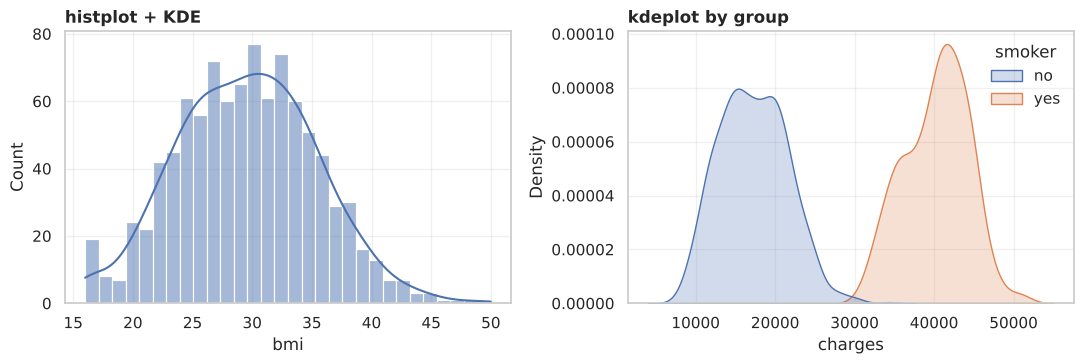

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(data=ins, x="bmi", bins=30, kde=True, ax=axes[0])
axes[0].set_title("histplot + KDE")
sns.kdeplot(data=ins, x="charges", hue="smoker", fill=True, common_norm=False, ax=axes[1])
axes[1].set_title("kdeplot by group")
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))</code></td><td>Two panels.</td></tr>
<tr><td><code>sns.histplot(data=ins, x=&quot;bmi&quot;, bins=30, kde=True, ax=axes[0])</code></td><td>kde=True adds the smooth curve over the bars.</td></tr>
<tr><td><code>axes[0].set_title(&quot;histplot + KDE&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>sns.kdeplot(data=ins, x=&quot;charges&quot;, hue=&quot;smoker&quot;, fill=True, common_norm=False, ax=axes[1])</code></td><td>common_norm=False: each group&#x27;s curve has area 1.</td></tr>
<tr><td><code>axes[1].set_title(&quot;kdeplot by group&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Tidy.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

### 16.2.2 ecdfplot and rugplot

> **📖 Definitions**
>
> **Rug plot**: a small tick on the axis for every single observation, showing exactly where the data lie.

**ECDF with a rug**

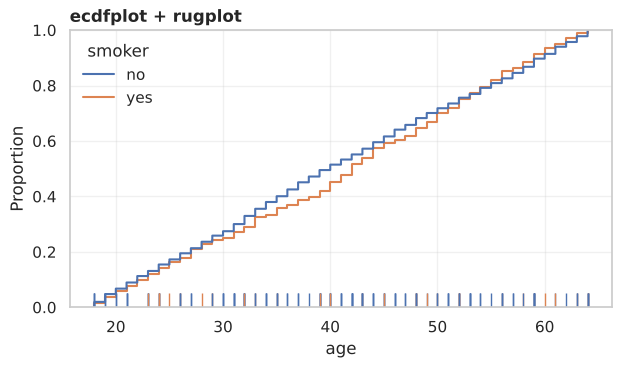

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.ecdfplot(data=ins, x="age", hue="smoker", ax=ax)
sns.rugplot(data=ins.sample(150, random_state=0), x="age", hue="smoker", height=0.05, ax=ax, legend=False)
ax.set_title("ecdfplot + rugplot")
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, ax = plt.subplots(figsize=(7, 3.6))</code></td><td>One panel.</td></tr>
<tr><td><code>sns.ecdfplot(data=ins, x=&quot;age&quot;, hue=&quot;smoker&quot;, ax=ax)</code></td><td>Cumulative proportion for each group.</td></tr>
<tr><td><code>sns.rugplot(data=ins.sample(150, random_state=0), x=&quot;age&quot;, hue=&quot;smoker&quot;, height=0.05, ax=ax, legend=False)</code></td><td>A rug of 150 sampled points.</td></tr>
<tr><td><code>ax.set_title(&quot;ecdfplot + rugplot&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

### 16.2.3 displot: small multiples of distributions

**One histogram per region and smoker status**

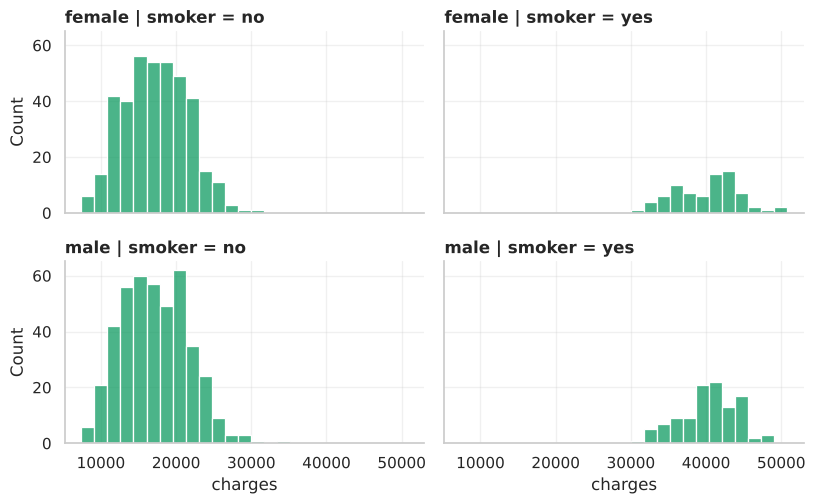

In [5]:
g = sns.displot(data=ins, x="charges", col="smoker", row="sex", bins=25,
                height=2.6, aspect=1.6, color="#0f9b62")
g.set_titles("{row_name} | smoker = {col_name}")
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>g = sns.displot(data=ins, x=&quot;charges&quot;, col=&quot;smoker&quot;, row=&quot;sex&quot;, bins=25,</code></td><td>Figure-level: col and row define the grid.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;height=2.6, aspect=1.6, color=&quot;#0f9b62&quot;)</code></td><td>Each panel 2.6 inches tall, 1.6 times as wide.</td></tr>
<tr><td><code>g.set_titles(&quot;{row_name} | smoker = {col_name}&quot;)</code></td><td>Panel titles from the grid variables.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

## 16.3 Relationship plots · *Beginner*

### 16.3.1 scatterplot and lineplot

> **📖 Definitions**
>
> **Confidence interval (in a line plot)**: Seaborn's `lineplot` aggregates repeated observations at each x into a mean and shades a 95% confidence interval for that mean, computed by bootstrapping.

**Scatter with four encodings; line with a confidence band**

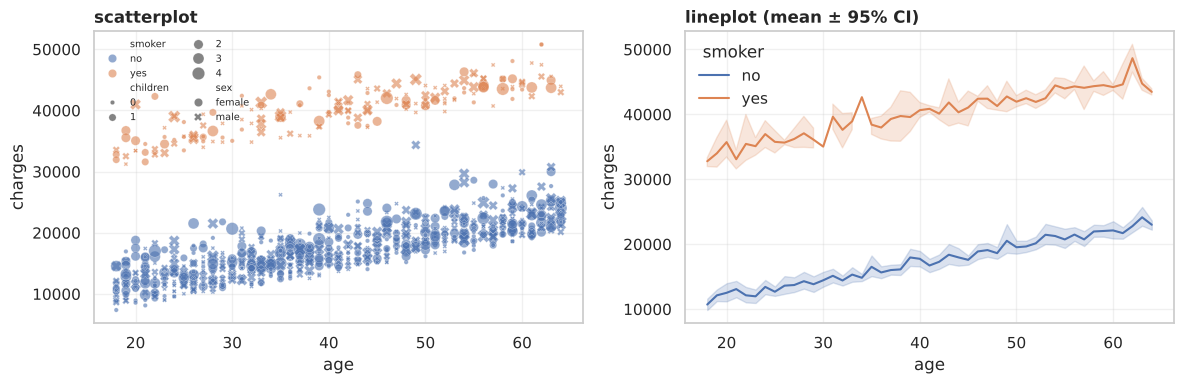

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=ins, x="age", y="charges", hue="smoker", style="sex", size="children",
                sizes=(10, 80), alpha=0.6, ax=axes[0])
axes[0].set_title("scatterplot")
axes[0].legend(fontsize=7, loc="upper left", ncol=2)
sns.lineplot(data=ins, x="age", y="charges", hue="smoker", errorbar=("ci", 95), ax=axes[1])
axes[1].set_title("lineplot (mean ± 95% CI)")
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(12, 4))</code></td><td>Two panels.</td></tr>
<tr><td><code>sns.scatterplot(data=ins, x=&quot;age&quot;, y=&quot;charges&quot;, hue=&quot;smoker&quot;, style=&quot;sex&quot;, size=&quot;children&quot;,</code></td><td>Four variables in one chart.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;sizes=(10, 80), alpha=0.6, ax=axes[0])</code></td><td>Range of marker sizes; transparency.</td></tr>
<tr><td><code>axes[0].set_title(&quot;scatterplot&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>axes[0].legend(fontsize=7, loc=&quot;upper left&quot;, ncol=2)</code></td><td>Compact legend.</td></tr>
<tr><td><code>sns.lineplot(data=ins, x=&quot;age&quot;, y=&quot;charges&quot;, hue=&quot;smoker&quot;, errorbar=(&quot;ci&quot;, 95), ax=axes[1])</code></td><td>Mean per age with a 95% CI band.</td></tr>
<tr><td><code>axes[1].set_title(&quot;lineplot (mean ± 95% CI)&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Tidy.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

### 16.3.2 relplot: faceted relationships

**Relationship split by region**

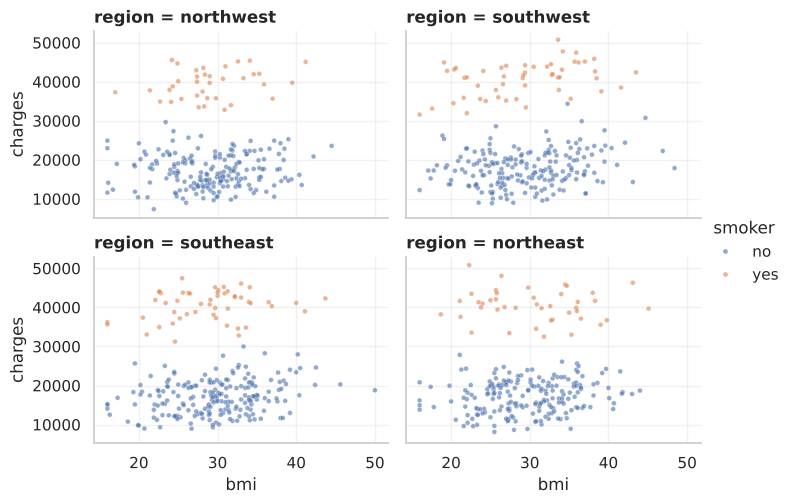

In [7]:
g = sns.relplot(data=ins, x="bmi", y="charges", hue="smoker", col="region", col_wrap=2,
                height=2.6, aspect=1.4, s=12, alpha=0.6)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>g = sns.relplot(data=ins, x=&quot;bmi&quot;, y=&quot;charges&quot;, hue=&quot;smoker&quot;, col=&quot;region&quot;, col_wrap=2,</code></td><td>One panel per region, 2 per row.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;height=2.6, aspect=1.4, s=12, alpha=0.6)</code></td><td>Panel size, marker size, transparency.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

## 16.4 Regression plots · *Intermediate*

### 16.4.1 regplot, residplot and lmplot

> **📖 Definitions**
>
> **Residual**: the difference between an observed value and the value a model predicts. **Residual plot**: residuals against the predictor; a shapeless cloud around zero means the model fits well, a curve or funnel means it is missing something.

**A fit and its residuals**

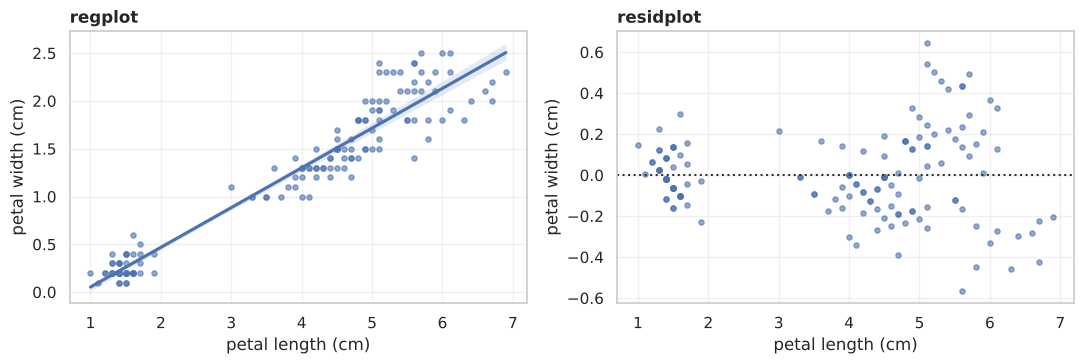

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.regplot(data=iris, x="petal length (cm)", y="petal width (cm)", ax=axes[0],
            scatter_kws={"s": 14, "alpha": 0.6})
axes[0].set_title("regplot")
sns.residplot(data=iris, x="petal length (cm)", y="petal width (cm)", ax=axes[1],
              scatter_kws={"s": 14, "alpha": 0.6})
axes[1].set_title("residplot")
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))</code></td><td>Two panels.</td></tr>
<tr><td><code>sns.regplot(data=iris, x=&quot;petal length (cm)&quot;, y=&quot;petal width (cm)&quot;, ax=axes[0],</code></td><td>Scatter + least-squares line + CI band.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;scatter_kws={&quot;s&quot;: 14, &quot;alpha&quot;: 0.6})</code></td><td>Smaller, transparent points.</td></tr>
<tr><td><code>axes[0].set_title(&quot;regplot&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>sns.residplot(data=iris, x=&quot;petal length (cm)&quot;, y=&quot;petal width (cm)&quot;, ax=axes[1],</code></td><td>Residuals of the same linear fit.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;scatter_kws={&quot;s&quot;: 14, &quot;alpha&quot;: 0.6})</code></td><td>Same styling.</td></tr>
<tr><td><code>axes[1].set_title(&quot;residplot&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Tidy.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

**lmplot: one regression per group**

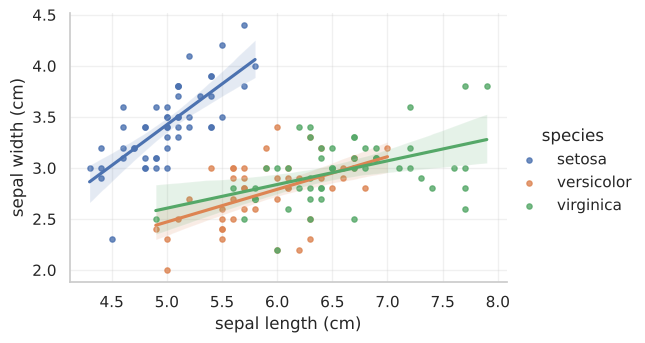

In [9]:
g = sns.lmplot(data=iris, x="sepal length (cm)", y="sepal width (cm)", hue="species",
               height=3.6, aspect=1.5, scatter_kws={"s": 14})
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>g = sns.lmplot(data=iris, x=&quot;sepal length (cm)&quot;, y=&quot;sepal width (cm)&quot;, hue=&quot;species&quot;,</code></td><td>Figure-level: one fit per hue level.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;height=3.6, aspect=1.5, scatter_kws={&quot;s&quot;: 14})</code></td><td>Size and marker styling.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

## 16.5 Categorical plots · *Beginner*

### 16.5.1 strip, swarm, box, violin and boxen

> **📖 Definitions**
>
> **Strip plot**: every observation drawn as a dot along a category axis, with random jitter so dots don't overlap. **Swarm plot**: like a strip plot, but dots are arranged so none overlap, which shows the distribution's shape. **Boxen (letter-value) plot**: an extended box plot that shows more quantiles; useful for large datasets.

**Five ways to show a numeric variable across categories**

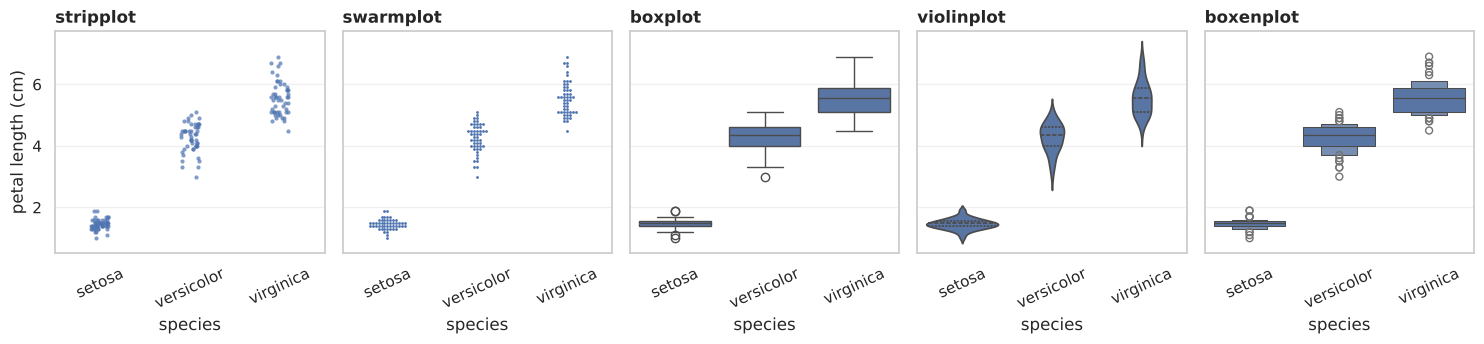

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), sharey=True)
kw = dict(data=iris, x="species", y="petal length (cm)")
sns.stripplot(**kw, ax=axes[0], size=3, alpha=0.7); axes[0].set_title("stripplot")
sns.swarmplot(**kw, ax=axes[1], size=2); axes[1].set_title("swarmplot")
sns.boxplot(**kw, ax=axes[2]); axes[2].set_title("boxplot")
sns.violinplot(**kw, ax=axes[3], inner="quart"); axes[3].set_title("violinplot")
sns.boxenplot(**kw, ax=axes[4]); axes[4].set_title("boxenplot")
for a in axes: a.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), sharey=True)</code></td><td>Five panels sharing the y-axis.</td></tr>
<tr><td><code>kw = dict(data=iris, x=&quot;species&quot;, y=&quot;petal length (cm)&quot;)</code></td><td>Shared arguments, unpacked with **kw below.</td></tr>
<tr><td><code>sns.stripplot(**kw, ax=axes[0], size=3, alpha=0.7); axes[0].set_title(&quot;stripplot&quot;)</code></td><td>Jittered dots.</td></tr>
<tr><td><code>sns.swarmplot(**kw, ax=axes[1], size=2); axes[1].set_title(&quot;swarmplot&quot;)</code></td><td>Non-overlapping dots (small markers so all 150 fit).</td></tr>
<tr><td><code>sns.boxplot(**kw, ax=axes[2]); axes[2].set_title(&quot;boxplot&quot;)</code></td><td>Quartiles and whiskers.</td></tr>
<tr><td><code>sns.violinplot(**kw, ax=axes[3], inner=&quot;quart&quot;); axes[3].set_title(&quot;violinplot&quot;)</code></td><td>Density with quartile lines.</td></tr>
<tr><td><code>sns.boxenplot(**kw, ax=axes[4]); axes[4].set_title(&quot;boxenplot&quot;)</code></td><td>Letter-value plot.</td></tr>
<tr><td><code>for a in axes: a.tick_params(axis=&quot;x&quot;, rotation=25)</code></td><td>Tilt the species names.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Tidy.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

### 16.5.2 barplot, pointplot and countplot

> **📖 Definitions**
>
> **Bar plot (Seaborn)**: the height of each bar is a summary statistic (by default the mean) of a numeric variable for that category, with an error bar (by default a 95% confidence interval). **Point plot**: the same estimate drawn as a point joined by lines. **Count plot**: bars showing how many rows fall in each category.

**Use pointplot** to compare how a mean changes across levels of two factors: non-parallel lines reveal an interaction.

**Means, interactions and counts**

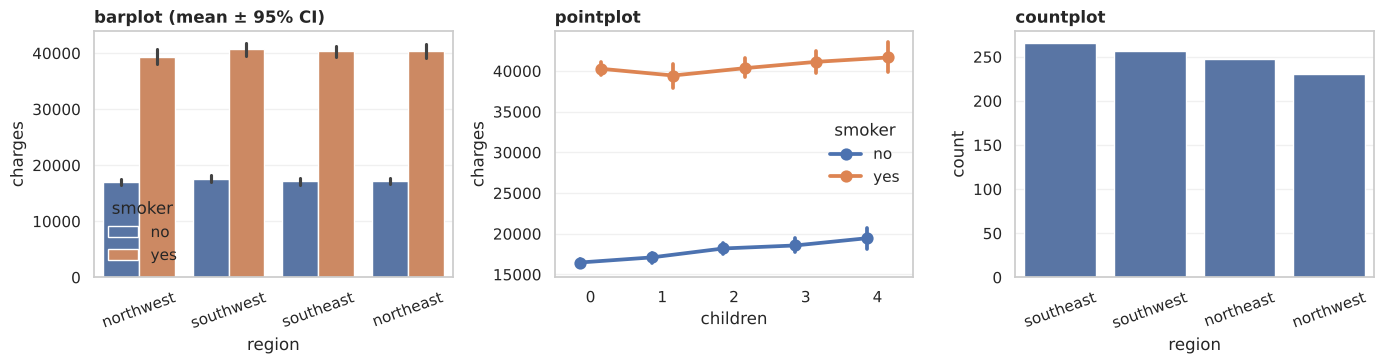

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.barplot(data=ins, x="region", y="charges", hue="smoker", ax=axes[0])
axes[0].set_title("barplot (mean ± 95% CI)"); axes[0].tick_params(axis="x", rotation=20)
sns.pointplot(data=ins, x="children", y="charges", hue="smoker", dodge=0.3, ax=axes[1])
axes[1].set_title("pointplot")
sns.countplot(data=ins, x="region", order=ins["region"].value_counts().index, ax=axes[2])
axes[2].set_title("countplot"); axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))</code></td><td>Three panels.</td></tr>
<tr><td><code>sns.barplot(data=ins, x=&quot;region&quot;, y=&quot;charges&quot;, hue=&quot;smoker&quot;, ax=axes[0])</code></td><td>Mean per group with 95% CI error bars.</td></tr>
<tr><td><code>axes[0].set_title(&quot;barplot (mean ± 95% CI)&quot;); axes[0].tick_params(axis=&quot;x&quot;, rotation=20)</code></td><td>Title; tilt labels.</td></tr>
<tr><td><code>sns.pointplot(data=ins, x=&quot;children&quot;, y=&quot;charges&quot;, hue=&quot;smoker&quot;, dodge=0.3, ax=axes[1])</code></td><td>dodge separates the two groups slightly.</td></tr>
<tr><td><code>axes[1].set_title(&quot;pointplot&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>sns.countplot(data=ins, x=&quot;region&quot;, order=ins[&quot;region&quot;].value_counts().index, ax=axes[2])</code></td><td>Bars ordered from most to least frequent.</td></tr>
<tr><td><code>axes[2].set_title(&quot;countplot&quot;); axes[2].tick_params(axis=&quot;x&quot;, rotation=20)</code></td><td>Title; tilt labels.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Tidy.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

### 16.5.3 catplot: faceted categorical plots

**Any categorical plot as a grid**

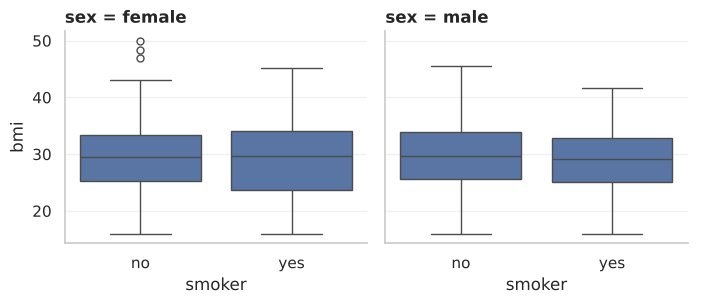

In [12]:
g = sns.catplot(data=ins, x="smoker", y="bmi", col="sex", kind="box",
                height=3.2, aspect=1.1)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>g = sns.catplot(data=ins, x=&quot;smoker&quot;, y=&quot;bmi&quot;, col=&quot;sex&quot;, kind=&quot;box&quot;,</code></td><td>kind selects the plot type.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;height=3.2, aspect=1.1)</code></td><td>Panel size.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

## 16.6 Matrix plots · *Intermediate*

### 16.6.1 heatmap and clustermap

> **📖 Definitions**
>
> **Clustermap**: a heatmap whose rows and columns are reordered by hierarchical clustering, with dendrograms (tree diagrams) showing which rows and columns are most similar.

**Correlation heatmap**

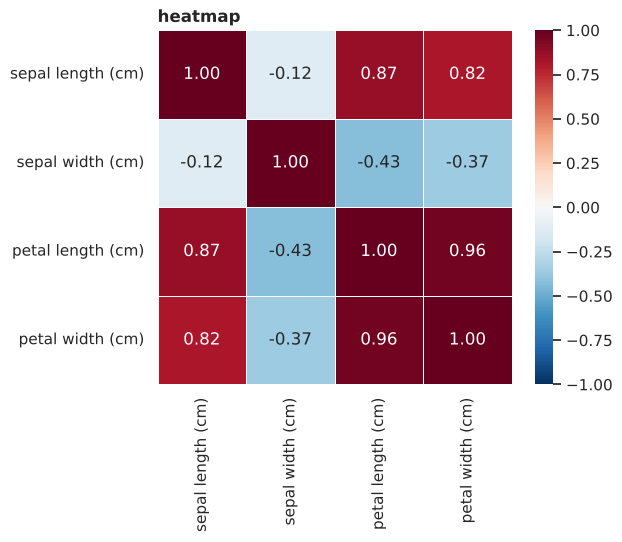

In [13]:
corr = iris.drop(columns=["target", "species"]).corr()
fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("heatmap")
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>corr = iris.drop(columns=[&quot;target&quot;, &quot;species&quot;]).corr()</code></td><td>4x4 correlation matrix.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(6, 4.6))</code></td><td>One panel.</td></tr>
<tr><td><code>sns.heatmap(corr, annot=True, fmt=&quot;.2f&quot;, cmap=&quot;RdBu_r&quot;, vmin=-1, vmax=1, center=0,</code></td><td>Numbers in cells, fixed -1..1 scale...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;square=True, linewidths=0.5, ax=ax)</code></td><td>...square cells with thin gaps.</td></tr>
<tr><td><code>ax.set_title(&quot;heatmap&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

**Clustermap groups similar rows and columns**

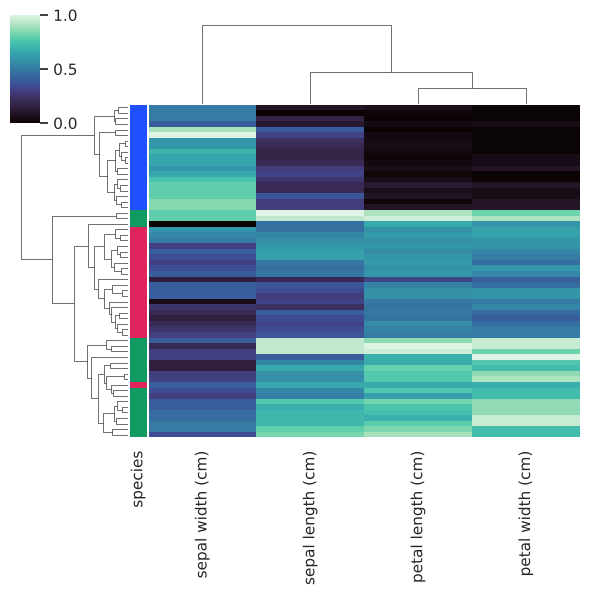

In [14]:
sub = iris.sample(60, random_state=1)
lut = dict(zip(sub["species"].unique(), ["#1f4fff", "#e0245e", "#0f9b62"]))
g = sns.clustermap(sub.drop(columns=["target", "species"]), standard_scale=1,
                   row_colors=sub["species"].map(lut), cmap="mako", figsize=(6, 6),
                   yticklabels=False)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>sub = iris.sample(60, random_state=1)</code></td><td>60 flowers keep the plot readable.</td></tr>
<tr><td><code>lut = dict(zip(sub[&quot;species&quot;].unique(), [&quot;#1f4fff&quot;, &quot;#e0245e&quot;, &quot;#0f9b62&quot;]))</code></td><td>Species -&gt; colour.</td></tr>
<tr><td><code>g = sns.clustermap(sub.drop(columns=[&quot;target&quot;, &quot;species&quot;]), standard_scale=1,</code></td><td>standard_scale=1 rescales each column to 0..1.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;row_colors=sub[&quot;species&quot;].map(lut), cmap=&quot;mako&quot;, figsize=(6, 6),</code></td><td>Colour strip showing each row&#x27;s species.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;yticklabels=False)</code></td><td>Hide 60 row labels.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

## 16.7 Multi-variable plots · *Intermediate*

### 16.7.1 pairplot and jointplot

> **📖 Definitions**
>
> **Pair plot (scatter-plot matrix)**: a grid with every variable plotted against every other, and each variable's distribution on the diagonal. **Joint plot**: one bivariate plot with each variable's marginal distribution drawn along its edges.

**pairplot**

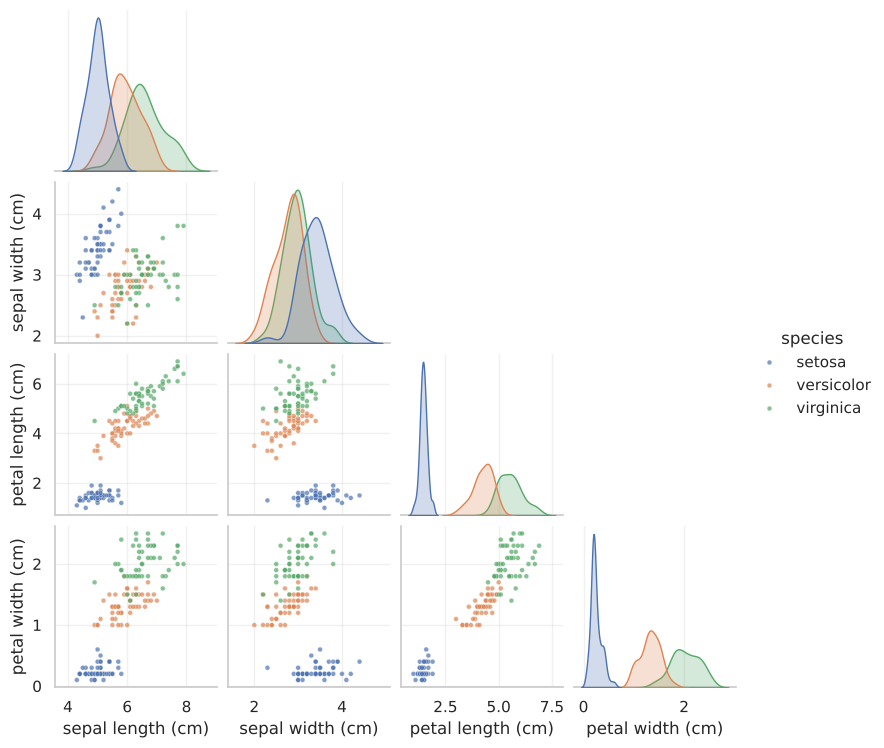

In [15]:
g = sns.pairplot(iris.drop(columns="target"), hue="species", corner=True, height=1.9,
                 plot_kws={"s": 12, "alpha": 0.7})
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>g = sns.pairplot(iris.drop(columns=&quot;target&quot;), hue=&quot;species&quot;, corner=True, height=1.9,</code></td><td>corner=True drops the redundant upper triangle.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;plot_kws={&quot;s&quot;: 12, &quot;alpha&quot;: 0.7})</code></td><td>Small, transparent points.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

**jointplot with three kinds**

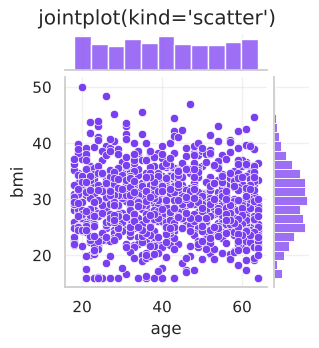

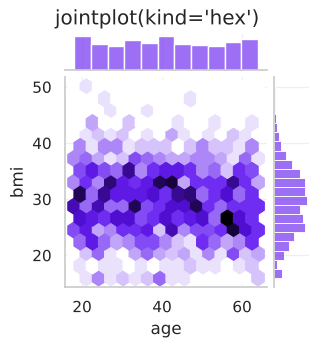

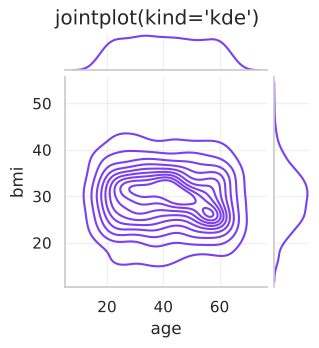

In [16]:
for kind in ["scatter", "hex", "kde"]:
    g = sns.jointplot(data=ins, x="age", y="bmi", kind=kind, height=3.4,
                      color="#7b3ff2")
    g.figure.suptitle(f"jointplot(kind='{kind}')", y=1.02)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>for kind in [&quot;scatter&quot;, &quot;hex&quot;, &quot;kde&quot;]:</code></td><td>Three styles.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;g = sns.jointplot(data=ins, x=&quot;age&quot;, y=&quot;bmi&quot;, kind=kind, height=3.4,</code></td><td>A joint plot of this kind.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;color=&quot;#7b3ff2&quot;)</code></td><td>One colour.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;g.figure.suptitle(f&quot;jointplot(kind=&#x27;{kind}&#x27;)&quot;, y=1.02)</code></td><td>Title above the figure.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw all three figures.</td></tr>
</table>
</details>

## 16.8 Styling Seaborn · *Intermediate*

**Themes, contexts and palettes**

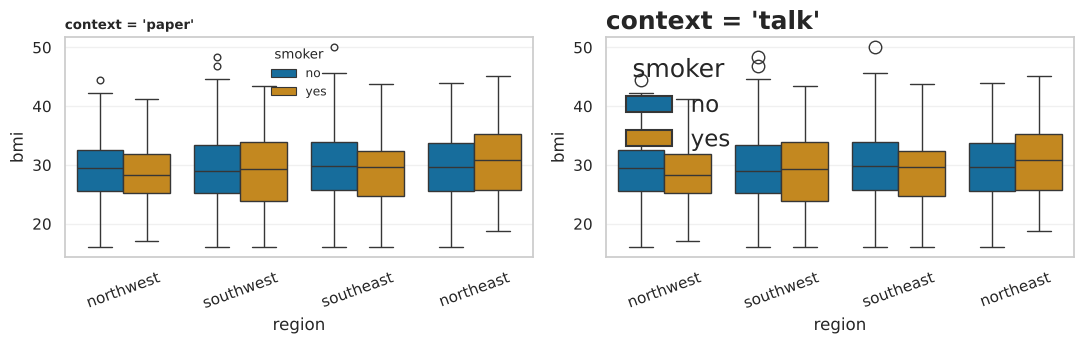

['#0173b2', '#de8f05', '#029e73', '#d55e00']


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, ctx in zip(axes, ["paper", "talk"]):
    with sns.plotting_context(ctx):
        sns.boxplot(data=ins, x="region", y="bmi", hue="smoker", palette="colorblind", ax=ax)
        ax.set_title(f"context = '{ctx}'")
        ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
print(sns.color_palette("colorblind").as_hex()[:4])

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))</code></td><td>Two panels.</td></tr>
<tr><td><code>for ax, ctx in zip(axes, [&quot;paper&quot;, &quot;talk&quot;]):</code></td><td>Two contexts.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;with sns.plotting_context(ctx):</code></td><td>Temporarily set fonts and line widths for this medium.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;sns.boxplot(data=ins, x=&quot;region&quot;, y=&quot;bmi&quot;, hue=&quot;smoker&quot;, palette=&quot;colorblind&quot;, ax=ax)</code></td><td>A colour-blind-safe palette.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;ax.set_title(f&quot;context = &#x27;{ctx}&#x27;&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;ax.tick_params(axis=&quot;x&quot;, rotation=20)</code></td><td>Tilt labels.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Tidy.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
<tr><td><code>print(sns.color_palette(&quot;colorblind&quot;).as_hex()[:4])</code></td><td>The palette&#x27;s first four colours as hex codes.</td></tr>
</table>
</details>

| Setting | Options | Effect |
|---|---|---|
| `sns.set_theme(style=)` | `"whitegrid"`, `"darkgrid"`, `"white"`, `"dark"`, `"ticks"` | background and grid |
| `context=` | `"paper"`, `"notebook"`, `"talk"`, `"poster"` | font and line sizes |
| `palette=` | `"deep"`, `"colorblind"`, `"viridis"`, `"rocket"`, `"mako"`, `"Set2"` | colours |

## 16.9 Saving Seaborn figures · *Beginner*

Axes-level plots live on a normal Matplotlib figure, so use `fig.savefig()`. Figure-level plots return a grid object with its own `savefig`.

**Saving both kinds**

In [18]:
fig, ax = plt.subplots(figsize=(4, 3))
sns.histplot(data=ins, x="bmi", ax=ax)
fig.savefig("bmi_hist.png", dpi=300, bbox_inches="tight")
plt.close(fig)
g = sns.relplot(data=ins, x="age", y="charges", hue="smoker", height=3)
g.savefig("age_charges.pdf")
plt.close(g.figure)
print("saved bmi_hist.png and age_charges.pdf")

saved bmi_hist.png and age_charges.pdf


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, ax = plt.subplots(figsize=(4, 3))</code></td><td>An axes-level plot on our own figure.</td></tr>
<tr><td><code>sns.histplot(data=ins, x=&quot;bmi&quot;, ax=ax)</code></td><td>Draw.</td></tr>
<tr><td><code>fig.savefig(&quot;bmi_hist.png&quot;, dpi=300, bbox_inches=&quot;tight&quot;)</code></td><td>Save via the figure.</td></tr>
<tr><td><code>plt.close(fig)</code></td><td>Close without displaying.</td></tr>
<tr><td><code>g = sns.relplot(data=ins, x=&quot;age&quot;, y=&quot;charges&quot;, hue=&quot;smoker&quot;, height=3)</code></td><td>A figure-level plot.</td></tr>
<tr><td><code>g.savefig(&quot;age_charges.pdf&quot;)</code></td><td>FacetGrid objects have their own savefig().</td></tr>
<tr><td><code>plt.close(g.figure)</code></td><td>Close it.</td></tr>
<tr><td><code>print(&quot;saved bmi_hist.png and age_charges.pdf&quot;)</code></td><td>Confirmation.</td></tr>
</table>
</details>

> **✍️ Try it yourself**
>
> 1. Use `catplot(kind="violin")` to show `charges` by `children`, split into columns by `smoker`.
> 2. Make a `jointplot` of `bmi` vs `charges` with `kind="reg"`. What does the fitted line suggest?
> 3. Draw a `clustermap` of the insurance numeric columns (scaled) for 80 random customers, with smokers marked in the row colours.
>
> *Worked solutions:* [solutions-parts-1-4.ipynb](../../solutions/solutions-parts-1-4.ipynb), section *Chapter 16*.

---

⬅️ [Chapter 15: The Matplotlib chart gallery](15-viz-mpl-gallery.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 17: Interactive charts with Plotly](17-viz-plotly.ipynb) ➡️